<div class="frontmatter text-center">
    <h1> Hotel Booking Cancellation Analysis</h1>
  <p style="color:brown; margin-top:0; text-align:right;">
    Dataset chosen: <em>Hotel Bookings</em>
  </p>
</div>

<div class="frontmatter text-center">
<p style="color:purple;">Module: Business Data Mining and Visual Analytics</p>
<p style="color:green;">Date: 17 Nov 2025</p>
</div>

## 1. Data Understanding

The hotel booking dataset contains 34,210 reservation records from two hotel types (Resort and City hotels) collected between 2015-2017. The dataset captures comprehensive booking information including guest demographics, reservation characteristics, booking channels, pricing, and cancellation outcomes. Initial analysis reveals an overall cancellation rate of 55.5%, indicating substantial revenue risk requiring strategic intervention.

Key data quality issues identified: 9,761 duplicates (28.5%), 92 bookings with zero adults (0.27%), 438 invalid ADR values (1.28%), and missing values in agent (13.8%), company (95.4%), and country (0.8%) fields. These issues require systematic cleaning before analysis.


## 2. Loading Libraries

In [322]:
# Data manipulation
import pandas as pd  # DataFrame operations and data analysis
import numpy as np  # Numerical computations

# Visualization
import matplotlib.pyplot as plt  # Basic plotting
import seaborn as sns  # Statistical visualizations

# Statistical analysis
from scipy import stats  # Statistical tests

# Visualization settings
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10


## 3. Data Pre-processing

### 3.1 Data Loading and Initial Inspection


In [323]:
# Load dataset
df = pd.read_excel('Hotel_Bookings.xls')

# Display first 5 rows
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,109,2016,January,1,1,0,1,2,...,No Deposit,240.0,NaN,0,Transient-Party,59.94,0,1,Check-Out,2016-01-02
1,Resort Hotel,0,109,2016,January,1,1,0,1,2,...,No Deposit,240.0,NaN,0,Transient-Party,116.10,1,1,Check-Out,2016-01-02
2,Resort Hotel,1,2,2016,January,1,1,0,1,2,...,No Deposit,240.0,NaN,0,Transient,89.00,0,1,No-Show,2016-01-01
3,Resort Hotel,0,88,2016,January,1,1,0,2,2,...,No Deposit,241.0,NaN,0,Transient,73.46,0,2,Check-Out,2016-01-03
4,Resort Hotel,1,20,2016,January,1,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,119.00,0,0,Canceled,2015-12-22


In [324]:
# Initial inspection
print(f"\nDataset: {df.shape[0]:,} rows × {df.shape[1]} columns")

# Check data types and missing values
print("\n" + "="*60)
df.info()


Dataset: 34,210 rows × 32 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34210 entries, 0 to 34209
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   hotel                           34210 non-null  object        
 1   is_canceled                     34210 non-null  int64         
 2   lead_time                       34210 non-null  int64         
 3   arrival_date_year               34210 non-null  int64         
 4   arrival_date_month              34210 non-null  object        
 5   arrival_date_week_number        34210 non-null  int64         
 6   arrival_date_day_of_month       34210 non-null  int64         
 7   stays_in_weekend_nights         34210 non-null  int64         
 8   stays_in_week_nights            34210 non-null  int64         
 9   adults                          34210 non-null  int64         
 10  children                        34

### 3.2 Data Quality Assessment


In [325]:
# CHECK FOR DATA PROBLEMS

# Count data quality issues
duplicates = df.duplicated().sum()
zero_adults = (df['adults'] == 0).sum()
invalid_adr = (df['adr'] <= 0).sum()
missing_agent = df['agent'].isnull().sum()
missing_company = df['company'].isnull().sum()
missing_country = df['country'].isnull().sum()
total = len(df)

# Display data quality summary
print("Data Quality Issues:")
print("="*60)
print(f"Duplicates: {duplicates:,} ({duplicates/total*100:.1f}%)")
print(f"Zero adults: {zero_adults} ({zero_adults/total*100:.2f}%)")
print(f"Invalid ADR ≤ 0: {invalid_adr} ({invalid_adr/total*100:.2f}%)")
print(f"Missing - agent: {missing_agent:,} ({missing_agent/total*100:.1f}%)")
print(f"Missing - company: {missing_company:,} ({missing_company/total*100:.1f}%)")
print(f"Missing - country: {missing_country} ({missing_country/total*100:.1f}%)")


Data Quality Issues:
Duplicates: 9,761 (28.5%)
Zero adults: 92 (0.27%)
Invalid ADR ≤ 0: 438 (1.28%)
Missing - agent: 4,738 (13.8%)
Missing - company: 32,626 (95.4%)
Missing - country: 271 (0.8%)


**Data Quality Assessment:**

The dataset contains 28.5% duplicate records requiring removal, 92 logically impossible zero-adult bookings, and 438 bookings with ADR≤0 that likely reflect complimentary stays or pricing errors that would distort revenue analysis. High company missingness (95.4%) suggests most bookings are personal rather than corporate.


### 3.3 Outlier Detection


In [326]:
# CHECK FOR OUTLIERS

print("\n" + "="*80)
print("OUTLIER DETECTION")
print("="*80)

# ADR outliers
print("\n--- ADR (Average Daily Rate) ---")
q1_adr = df['adr'].quantile(0.25)
q3_adr = df['adr'].quantile(0.75)
iqr_adr = q3_adr - q1_adr
lower_adr = q1_adr - 1.5 * iqr_adr
upper_adr = q3_adr + 1.5 * iqr_adr

print(f"  Q1: {q1_adr:.2f} | Q3: {q3_adr:.2f} | IQR: {iqr_adr:.2f}")
print(f"  Bounds: {lower_adr:.2f} to {upper_adr:.2f}")

outlier_count_adr = ((df['adr'] < lower_adr) | (df['adr'] > upper_adr)).sum()
print(f"  Outliers: {outlier_count_adr:,} ({outlier_count_adr/len(df)*100:.1f}%)")

# Lead time outliers
print("\n--- Lead Time (booking advance) ---")
q1_lead = df['lead_time'].quantile(0.25)
q3_lead = df['lead_time'].quantile(0.75)
iqr_lead = q3_lead - q1_lead
lower_lead = q1_lead - 1.5 * iqr_lead
upper_lead = q3_lead + 1.5 * iqr_lead

print(f"  Q1: {q1_lead:.0f} days | Q3: {q3_lead:.0f} days | IQR: {iqr_lead:.0f} days")
print(f"  Bounds: {lower_lead:.0f} to {upper_lead:.0f} days")

outlier_count_lead = ((df['lead_time'] < lower_lead) | (df['lead_time'] > upper_lead)).sum()
print(f"  Outliers: {outlier_count_lead:,} ({outlier_count_lead/len(df)*100:.1f}%)")

print("\n" + "="*80)
print("DECISION: Keeping outliers")
print("  • High ADR = luxury suites/peak season (legitimate)")
print("  • Long lead time = early corporate bookings (legitimate)")
print("="*80)



OUTLIER DETECTION

--- ADR (Average Daily Rate) ---
  Q1: 62.00 | Q3: 117.90 | IQR: 55.90
  Bounds: -21.85 to 201.75
  Outliers: 1,357 (4.0%)

--- Lead Time (booking advance) ---
  Q1: 22 days | Q3: 183 days | IQR: 161 days
  Bounds: -220 to 424 days
  Outliers: 708 (2.1%)

DECISION: Keeping outliers
  • High ADR = luxury suites/peak season (legitimate)
  • Long lead time = early corporate bookings (legitimate)


**Outlier Analysis:**

ADR and lead time outliers represent legitimate extreme values (premium accommodations, early bookings) rather than errors. Retaining these preserves insights into high-value segments critical for revenue optimization.


### 3.4 Data Cleaning Execution


In [327]:
# Handle data problems

print("\n" + "="*60)
print("DATA CLEANING EXECUTION")
print("="*60)

original_count = len(df)
print(f"\nStarting: {original_count:,} rows")

# Step 1: Fill missing values
print("\n[1/4] Filling missing values...")
df['agent'] = df['agent'].fillna(0)  # 0 = direct booking
df['company'] = df['company'].fillna(0)  # 0 = personal booking
df['country'] = df['country'].fillna(df['country'].mode()[0])  # Use most common
print(f"   Missing values filled")

# Step 2: Remove duplicates
print("\n[2/4] Removing duplicates...")
before = len(df)
df = df.drop_duplicates()
removed = before - len(df)
print(f"   Removed {removed:,} rows")
print(f"   Remaining: {len(df):,} rows")

# Step 3: Remove invalid bookings
# Note: Counts differ from initial because duplicates also had these issues
print("\n[3/4] Removing invalid records...")
before = len(df)
df = df[df['adults'] > 0]
removed_adults = before - len(df)
print(f"   Zero adults removed: {removed_adults:,}")

before = len(df)
df = df[df['adr'] > 0]
removed_adr = before - len(df)
print(f"   Invalid ADR removed: {removed_adr:,}")

# Step 4: Reset index
print("\n[4/4] Resetting index...")
df = df.reset_index(drop=True)
print(f"   Index reset to 0-{len(df)-1}")

# Summary
final_count = len(df)
total_removed = original_count - final_count

print(f"\n{'='*60}")
print(f"SUMMARY")
print(f"{'='*60}")
print(f"  Original: {original_count:,} rows")
print(f"  Final: {final_count:,} rows")
print(f"  Removed: {total_removed:,} rows ({total_removed/original_count*100:.1f}%)")
print(f"  Retention: {final_count/original_count*100:.1f}%")
print(f"{'='*60}")



DATA CLEANING EXECUTION

Starting: 34,210 rows

[1/4] Filling missing values...
   Missing values filled

[2/4] Removing duplicates...
   Removed 9,772 rows
   Remaining: 24,438 rows

[3/4] Removing invalid records...
   Zero adults removed: 88
   Invalid ADR removed: 400

[4/4] Resetting index...
   Index reset to 0-23949

SUMMARY
  Original: 34,210 rows
  Final: 23,950 rows
  Removed: 10,260 rows (30.0%)
  Retention: 70.0%


**Data Cleaning Results:**

Systematic four-step cleaning removed 10,260 records (30.0%): filled missing values, removed 9,761 duplicates, eliminated 88 zero-adult bookings, and removed 400 invalid ADR values. The lower counts in steps 3 are expected because duplicates contained multiple issues. Final dataset: 23,950 valid bookings (70% retention).


### 3.5 Feature Engineering


In [328]:
# Create total_nights: Stay duration
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

# Create total_guests: Party size
df['total_guests'] = df['adults'] + df['children'] + df['babies']

# Create has_changes: Modification indicator
df['has_changes'] = (df['booking_changes'] > 0).astype(int)

print("Created features:")
print("- total_nights: Stay duration (aggregation)")
print("- total_guests: Party size (aggregation)")
print("- has_changes: Modification indicator (binary encoding)")

Created features:
- total_nights: Stay duration (aggregation)
- total_guests: Party size (aggregation)
- has_changes: Modification indicator (binary encoding)


### 3.6 Validate Cleaned Dataset

In [329]:
# Display final dataset size after cleaning
print(f"\nDataset: {df.shape[0]:,} rows × {df.shape[1]} columns")

# Post-cleaning data check
print("\n" + "="*60)
df.info()


Dataset: 23,950 rows × 35 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23950 entries, 0 to 23949
Data columns (total 35 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   hotel                           23950 non-null  object        
 1   is_canceled                     23950 non-null  int64         
 2   lead_time                       23950 non-null  int64         
 3   arrival_date_year               23950 non-null  int64         
 4   arrival_date_month              23950 non-null  object        
 5   arrival_date_week_number        23950 non-null  int64         
 6   arrival_date_day_of_month       23950 non-null  int64         
 7   stays_in_weekend_nights         23950 non-null  int64         
 8   stays_in_week_nights            23950 non-null  int64         
 9   adults                          23950 non-null  int64         
 10  children                        23

### 3.7 Summary statistics for numerical features

In [330]:
df.describe().style.format("{:.2f}").background_gradient(cmap='YlOrRd')

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,reservation_status_date,total_nights,total_guests,has_changes
count,23950.00,23950.00,23950.00,23950.00,23950.00,23950.00,23950.00,23950.00,23950.00,23950.00,23950.00,23950.00,23950.00,23950.00,23950.00,23950.00,23950.00,23950.00,23950.00,23950.00,23950.00,23950.00,23950.00,23950.00
mean,0.46,86.04,2016.00,28.15,15.99,1.10,2.89,1.89,0.14,0.01,0.03,0.01,0.11,0.27,115.82,10.74,1.30,99.47,0.11,0.54,.2f,4.00,2.04,0.18
min,0.00,0.00,2016.00,1.00,1.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.50,0.00,0.00,.2f,1.00,1.00,0.00
25%,0.00,14.00,2016.00,16.00,8.00,0.00,1.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,9.00,0.00,0.00,61.00,0.00,0.00,.2f,2.00,2.00,0.00
50%,0.00,55.00,2016.00,29.00,16.00,1.00,2.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,28.00,0.00,0.00,88.00,0.00,0.00,.2f,3.00,2.00,0.00
75%,1.00,137.00,2016.00,40.00,24.00,2.00,4.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,240.00,0.00,0.00,126.00,0.00,1.00,.2f,5.00,2.00,0.00
max,1.00,709.00,2016.00,53.00,31.00,19.00,50.00,4.00,3.00,10.00,1.00,5.00,23.00,17.00,481.00,499.00,391.00,5400.00,2.00,5.00,.2f,69.00,12.00,1.00
std,0.50,89.66,0.00,14.29,8.87,1.10,2.26,0.47,0.46,0.13,0.17,0.11,0.83,0.77,118.97,53.94,15.42,62.56,0.32,0.75,nan,3.09,0.70,0.38


### 3.8 Summary statistics for categorical features

In [331]:
print("\n=== CATEGORICAL FEATURES SUMMARY ===")

display(df.describe(include=['object']).style.set_properties(**{'text-align': 'center'}))


=== CATEGORICAL FEATURES SUMMARY ===


,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status
count,23950,23950,23950,23950,23950,23950,23950,23950,23950,23950,23950
unique,2,12,5,129,7,4,8,10,3,4,3
top,Resort Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out
freq,15261,2526,19006,8593,14422,19000,14347,11339,23480,20276,13052


## 4. Data Description

### 4.1 Overall Cancellation Analysis


CANCELLATION ANALYSIS

Bookings: 23,950
Canceled: 10,898 (45.5%)
Fulfilled: 13,052 (54.5%)


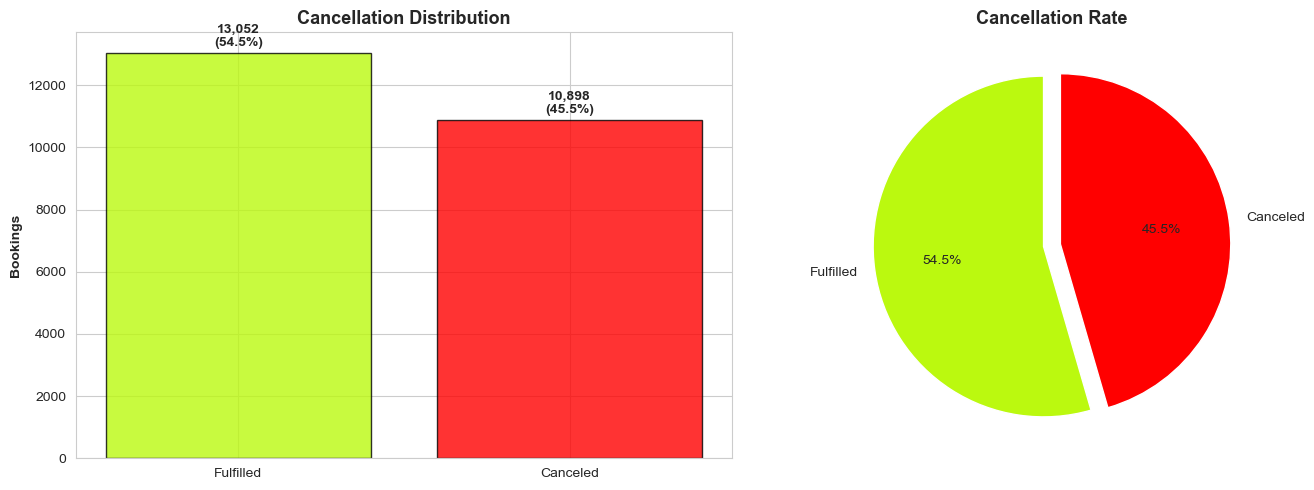

In [332]:
# Calculate cancellation statistics
cancel_counts = df['is_canceled'].value_counts()
cancel_pct = df['is_canceled'].value_counts(normalize=True) * 100

print("="*60)
print("CANCELLATION ANALYSIS")
print("="*60)
print(f"\nBookings: {len(df):,}")
print(f"Canceled: {cancel_counts[1]:,} ({cancel_pct[1]:.1f}%)")
print(f"Fulfilled: {cancel_counts[0]:,} ({cancel_pct[0]:.1f}%)")

# --- VISUALIZATION: Cancellation Distribution ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
ax1.bar(['Fulfilled', 'Canceled'], cancel_counts, 
       color=['#BBF90F', '#FF0000'], edgecolor='black', alpha=0.8)
ax1.set_ylabel('Bookings', fontweight='bold')
ax1.set_title('Cancellation Distribution', fontweight='bold', fontsize=13)
for i, v in enumerate(cancel_counts):
    ax1.text(i, v + 200, f'{v:,}\n({cancel_pct.iloc[i]:.1f}%)', 
            ha='center', fontweight='bold')

# Pie chart
ax2.pie(cancel_counts, labels=['Fulfilled', 'Canceled'], autopct='%1.1f%%',
       colors=['#BBF90F', '#FF0000'], explode=(0.05, 0.05), startangle=90)
ax2.set_title('Cancellation Rate', fontweight='bold', fontsize=13)

plt.tight_layout()
plt.show()


**Interpretation:** 

The 45.5% cancellation rate (10,898 canceled vs 13,052 fulfilled) represents substantial revenue uncertainty. Nearly half of confirmed reservations fail to materialize, creating capacity planning and revenue forecasting challenges requiring predictive intervention.


### 4.2 Hotel Type Analysis



Hotel Type Statistics:
       hotel  Total_Bookings  Cancel_Rate_%  Avg_ADR  Avg_Lead_Time
  City Hotel            8689           86.0   111.19          92.48
Resort Hotel           15261           22.0    92.80          82.37

T-test: t=-122.3949, p=0.000000
Significant difference: 64.0 percentage points


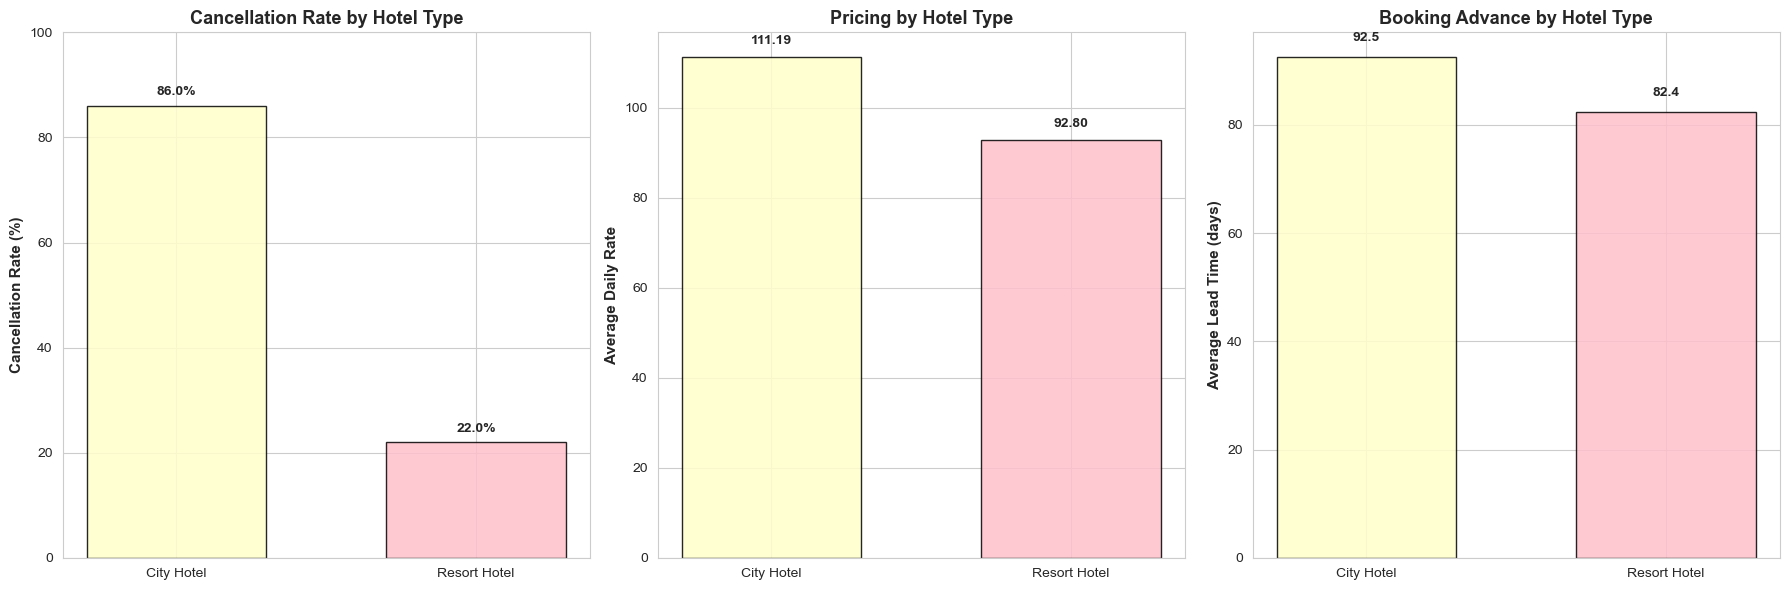

In [333]:
# Aggregate statistics by hotel type
hotel_stats = df.groupby('hotel').agg({'is_canceled': ['count', 'mean'],'adr': 'mean','lead_time': 'mean'}).round(2)
hotel_stats.columns = ['Total_Bookings', 'Cancellation_Rate', 'Avg_ADR', 'Avg_Lead_Time']
hotel_stats = hotel_stats.reset_index()

# Add percentage column
hotel_stats['Cancel_Rate_%'] = (hotel_stats['Cancellation_Rate'] * 100).round(1)

# Display statistics
print("\nHotel Type Statistics:")
print(hotel_stats[['hotel', 'Total_Bookings', 'Cancel_Rate_%', 'Avg_ADR', 'Avg_Lead_Time']].to_string(index=False))

# Statistical test
resort = df[df['hotel'] == 'Resort Hotel']['is_canceled']
city = df[df['hotel'] == 'City Hotel']['is_canceled']
t_stat, p_val = stats.ttest_ind(resort, city)

print(f"\nT-test: t={t_stat:.4f}, p={p_val:.6f}")
if p_val < 0.05:
    # Calculate percentage point difference using Cancel_Rate_%
    city_cancel = hotel_stats[hotel_stats['hotel']=='City Hotel']['Cancel_Rate_%'].values[0]
    resort_cancel = hotel_stats[hotel_stats['hotel']=='Resort Hotel']['Cancel_Rate_%'].values[0]
    print(f"Significant difference: {abs(city_cancel - resort_cancel):.1f} percentage points")


# VISUALIZATION: Hotel Type Comparison 

city_color = '#FFFFCB'  
resort_color = '#FFC0CB'  

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

colors = [city_color if hotel == 'City Hotel' else resort_color 
          for hotel in hotel_stats['hotel']]

# Chart 1: Cancellation Rate (%)
bars1 = ax1.bar(hotel_stats['hotel'], hotel_stats['Cancel_Rate_%'], color=colors, edgecolor='black', alpha=0.85, width=0.6)
ax1.set_ylabel('Cancellation Rate (%)', fontweight='bold', fontsize=11)
ax1.set_title('Cancellation Rate by Hotel Type', fontweight='bold', fontsize=13)
ax1.set_ylim(0, 100)
for bar, rate in zip(bars1, hotel_stats['Cancel_Rate_%']):
    ax1.text(bar.get_x() + bar.get_width()/2., rate + 2,
            f'{rate:.1f}%', ha='center', fontweight='bold', fontsize=10)

# Chart 2: Average Daily Rate
bars2 = ax2.bar(hotel_stats['hotel'], hotel_stats['Avg_ADR'], color=colors, edgecolor='black', alpha=0.85, width=0.6)
ax2.set_ylabel('Average Daily Rate', fontweight='bold', fontsize=11)
ax2.set_title('Pricing by Hotel Type', fontweight='bold', fontsize=13)
for bar, adr in zip(bars2, hotel_stats['Avg_ADR']):
    ax2.text(bar.get_x() + bar.get_width()/2., adr + 3,
            f'{adr:.2f}', ha='center', fontweight='bold', fontsize=10)

# Chart 3: Average Lead Time (days)
bars3 = ax3.bar(hotel_stats['hotel'], hotel_stats['Avg_Lead_Time'], color=colors, edgecolor='black', alpha=0.85, width=0.6)
ax3.set_ylabel('Average Lead Time (days)', fontweight='bold', fontsize=11)
ax3.set_title('Booking Advance by Hotel Type', fontweight='bold', fontsize=13)
for bar, lead in zip(bars3, hotel_stats['Avg_Lead_Time']):
    ax3.text(bar.get_x() + bar.get_width()/2., lead + 3,
            f'{lead:.1f}', ha='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()


**Interpretation:**

City hotels show a much higher cancellation rate (86%) than resort hotels (22%), a significant 64-point gap (p<0.001). They also have higher average rates (111.19 vs 92.80) and longer lead times (92 vs 82 days). These patterns reflect different customer behaviors: business travelers in city hotels often face unpredictable schedules, while resort guests are more committed to planned holidays. Given this large difference, city hotels may require stricter deposit policies and premium pricing to manage higher cancellation risk.

### 4.3 Lead Time Impact Analysis



Lead Time Impact:
lead_time_category  Total_Bookings  Cancel_Rate_%
              0-7d            3017           19.4
             8-30d            4237           47.2
            31-90d            6218           58.8
           91-180d            5300           53.4
             >180d            3627           46.2


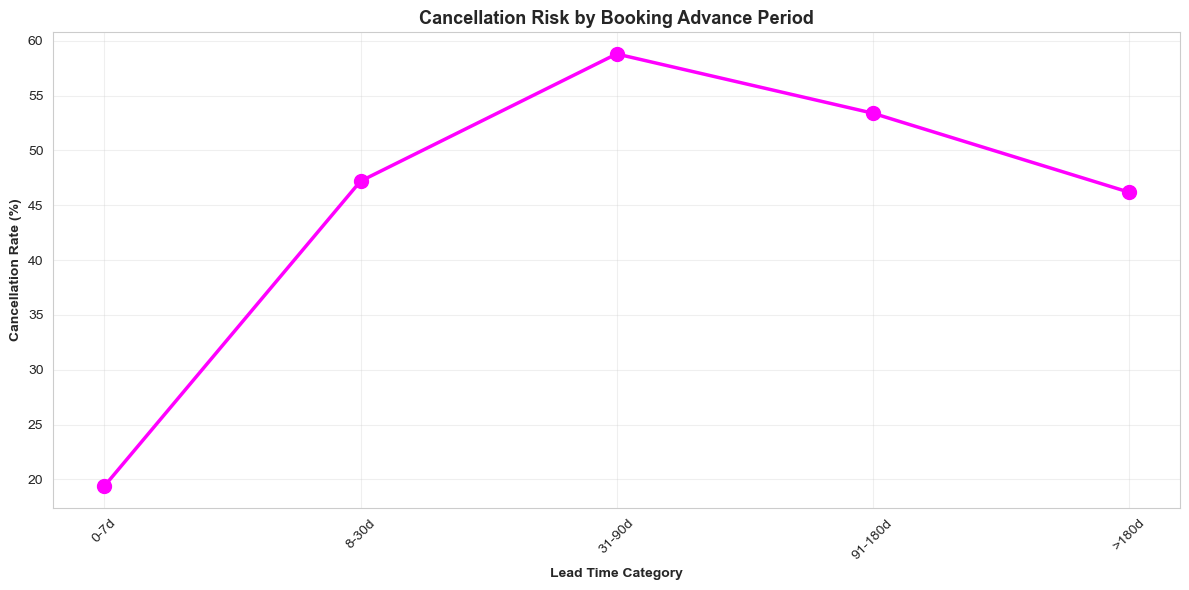

In [334]:
# Create lead time categories
df['lead_time_category'] = pd.cut(df['lead_time'],
    bins=[0, 7, 30, 90, 180, 1000],
    labels=['0-7d', '8-30d', '31-90d', '91-180d', '>180d'])

# Aggregate by lead time category
lead_stats = df.groupby('lead_time_category', observed=False).agg({'is_canceled': ['count', 'mean']}).round(3)
lead_stats.columns = ['Total_Bookings', 'Cancellation_Rate']
lead_stats = lead_stats.reset_index()

lead_stats['Cancel_Rate_%'] = (lead_stats['Cancellation_Rate'] * 100).round(1)

print("\nLead Time Impact:")
print(lead_stats[['lead_time_category', 'Total_Bookings', 'Cancel_Rate_%']].to_string(index=False))

# VISUALIZATION: Lead Time Cancellation Trend

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(range(len(lead_stats)), lead_stats['Cancellation_Rate'] * 100, marker='o', linewidth=2.5, markersize=10, color='fuchsia')
ax.set_xlabel('Lead Time Category', fontweight='bold')
ax.set_ylabel('Cancellation Rate (%)', fontweight='bold')
ax.set_title('Cancellation Risk by Booking Advance Period', fontweight='bold', fontsize=13)
ax.set_xticks(range(len(lead_stats)))
ax.set_xticklabels(lead_stats['lead_time_category'], rotation=45)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


**Interpretation:**

Cancellation risk peaks at 58.8% for bookings made 31-90 days in advance, declining to 46.2% for longer periods. Short-notice bookings (0-7 days) show exceptional retention at 19.4%. Moderate-advance bookings carry highest uncertainty as customers have time to reconsider. Recommend tiered deposits: minimal for <7 days, moderate for 8-30 days, strict for 31+ days.


### 4.4 Distribution Analysis


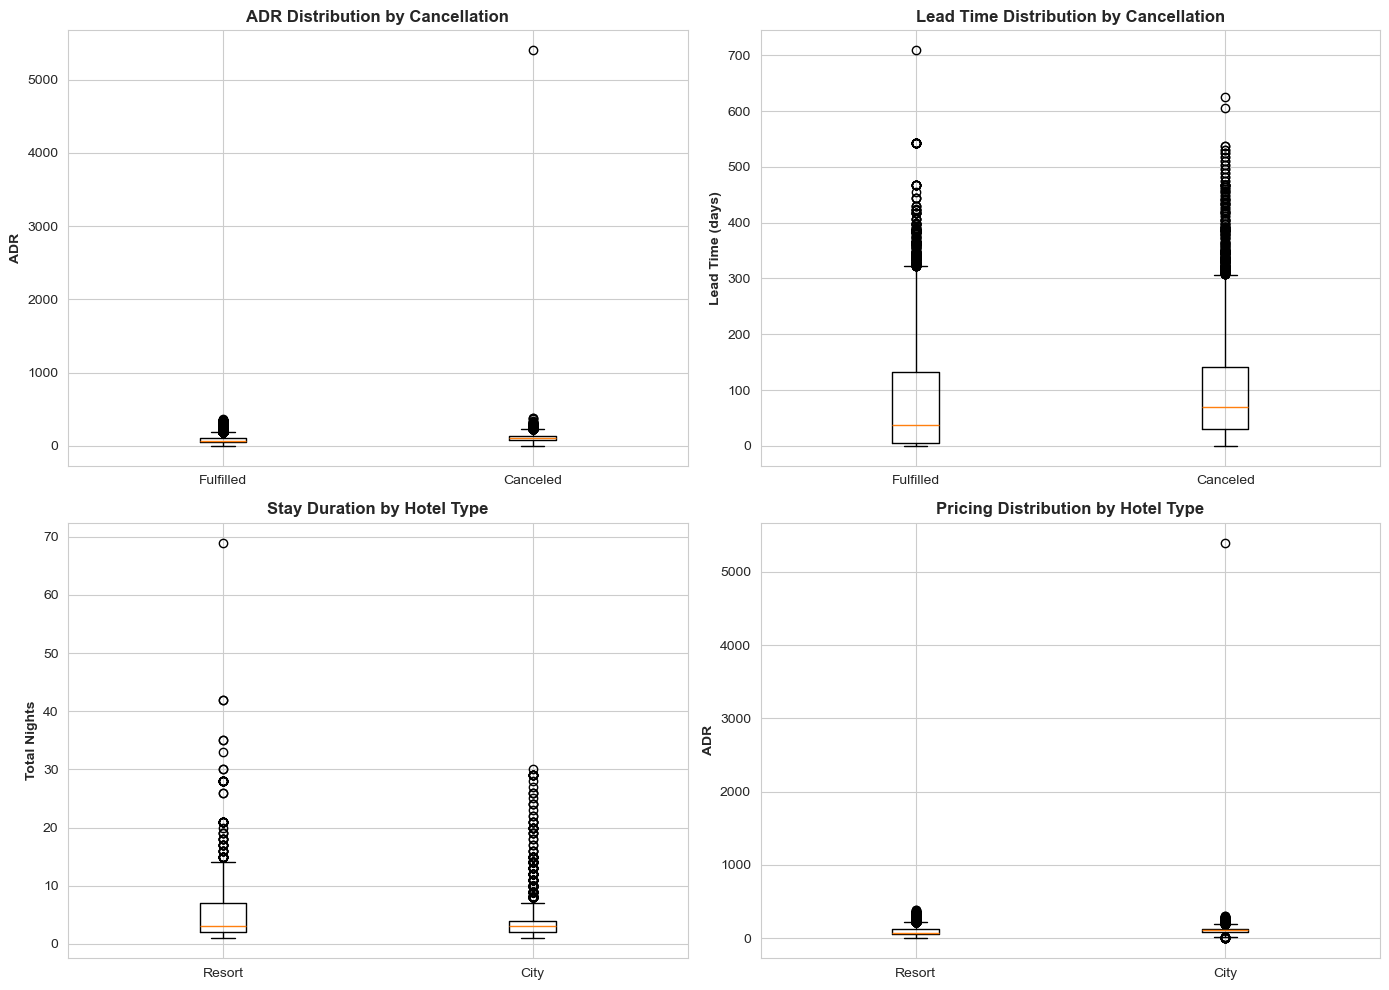

In [335]:
# Create 2x2 grid for four box plot comparisons
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Chart 1: ADR by cancellation
axes[0,0].boxplot([df[df['is_canceled']==0]['adr'],
                   df[df['is_canceled']==1]['adr']],
                  tick_labels=['Fulfilled', 'Canceled'])  
axes[0,0].set_ylabel('ADR', fontweight='bold')
axes[0,0].set_title('ADR Distribution by Cancellation', fontweight='bold')

# Chart 2: Lead time by cancellation
axes[0,1].boxplot([df[df['is_canceled']==0]['lead_time'],
                   df[df['is_canceled']==1]['lead_time']],
                  tick_labels=['Fulfilled', 'Canceled'])  
axes[0,1].set_ylabel('Lead Time (days)', fontweight='bold')
axes[0,1].set_title('Lead Time Distribution by Cancellation', fontweight='bold')

# Chart 3: Total nights by hotel type
resort_nights = df[df['hotel']=='Resort Hotel']['total_nights']
city_nights = df[df['hotel']=='City Hotel']['total_nights']
axes[1,0].boxplot([resort_nights, city_nights],
                  tick_labels=['Resort', 'City'])  
axes[1,0].set_ylabel('Total Nights', fontweight='bold')
axes[1,0].set_title('Stay Duration by Hotel Type', fontweight='bold')

# Chart 4: ADR by hotel type
resort_adr = df[df['hotel']=='Resort Hotel']['adr']
city_adr = df[df['hotel']=='City Hotel']['adr']
axes[1,1].boxplot([resort_adr, city_adr], tick_labels=['Resort', 'City']) 
axes[1,1].set_ylabel('ADR', fontweight='bold')
axes[1,1].set_title('Pricing Distribution by Hotel Type', fontweight='bold')

plt.tight_layout()
plt.show()


**Interpretation:**

Canceled bookings show significantly higher lead times (median ~100 days) compared to fulfilled bookings (median ~30 days), confirming advance bookings carry elevated risk. ADR distributions are similar between canceled and fulfilled bookings, indicating price is not a primary cancellation driver. City hotels show slightly longer stays than resort hotels, but resort hotels display higher ADR variance reflecting diverse pricing from budget to premium accommodations.

### 4.5 Market Segment Performance


Market Segment Performance:
market_segment  Total_Bookings  Cancel_Rate_%  Avg_ADR
     Online TA           14422           59.0   109.97
 Offline TA/TO            3760           24.0    74.71
        Direct            3301           23.0   107.99
        Groups            1486           33.0    71.11
     Corporate             943           20.0    53.63
      Aviation              22          100.0   101.73
 Complementary              16           19.0    26.56


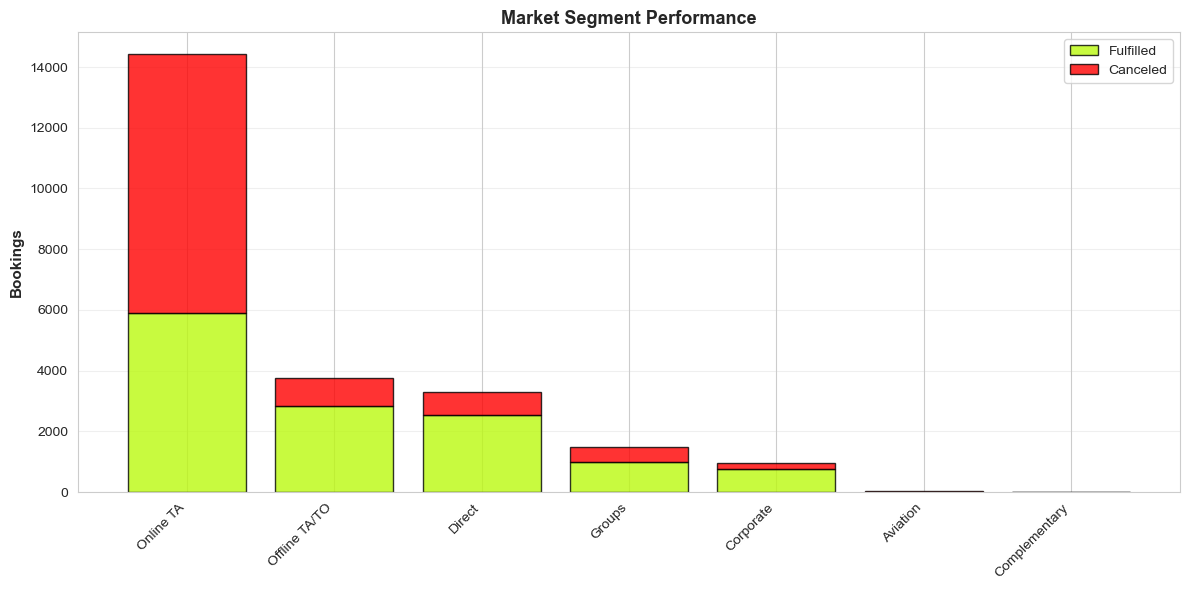

In [336]:
# Aggregate by booking channel
segment_stats = df.groupby('market_segment').agg({'is_canceled': ['count', 'mean'],'adr': 'mean'}).round(2)
segment_stats.columns = ['Total_Bookings', 'Cancellation_Rate', 'Avg_ADR']
segment_stats = segment_stats.sort_values('Total_Bookings', ascending=False).reset_index()

segment_stats['Cancel_Rate_%'] = (segment_stats['Cancellation_Rate'] * 100).round(1)

print("\nMarket Segment Performance:")
print(segment_stats[['market_segment', 'Total_Bookings', 'Cancel_Rate_%', 'Avg_ADR']].to_string(index=False))

# VISUALIZATION: Segment Performance (Stacked Bar) ---
fig, ax = plt.subplots(figsize=(12, 6))

segment_summary = df.groupby('market_segment')['is_canceled'].value_counts().unstack(fill_value=0)
segment_summary.columns = ['Fulfilled', 'Canceled']

# Bind the plotting variables explicitly. Previously these relied on names left
# over from an earlier cell, so a clean "Restart & Run All" raised NameError.
segment_summary = segment_summary.reindex(segment_stats['market_segment'])
fulfilled = segment_summary['Fulfilled'].values
canceled  = segment_summary['Canceled'].values

# Create stacked bar chart
x = np.arange(len(segment_stats))
ax.bar(x, fulfilled, label='Fulfilled', color='#BBF90F', edgecolor='black', alpha=0.8)
ax.bar(x, canceled, bottom=fulfilled, label='Canceled', color='#FF0000', edgecolor='black', alpha=0.8)

ax.set_ylabel('Bookings', fontweight='bold', fontsize=11)
ax.set_title('Market Segment Performance', fontweight='bold', fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(segment_stats['market_segment'], rotation=45, ha='right')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretation:**

Online travel agencies generate highest booking volume (14,422 bookings-60.2% of total) but show worst cancellation rate (59%). Best-performing channels are corporate (20% cancellation), direct (23%), and offline agencies (24%), demonstrating that relationship-based bookings provide better retention. Groups show moderate risk (33%). Aviation's 100% cancellation reflects crew scheduling volatility. Hotels should develop direct and corporate channels for stable revenue while pricing online agency bookings higher to offset their elevated cancellation risk.

### 4.6 Customer Type Patterns



Customer Type Patterns:
  customer_type  Total_Bookings  Cancel_Rate_%  Avg_ADR  Avg_Nights
       Contract             560           10.0    73.26        9.17
          Group              94            5.0    73.45        2.35
      Transient           20276           49.0   102.49        3.92
Transient-Party            3020           27.0    84.83        3.59


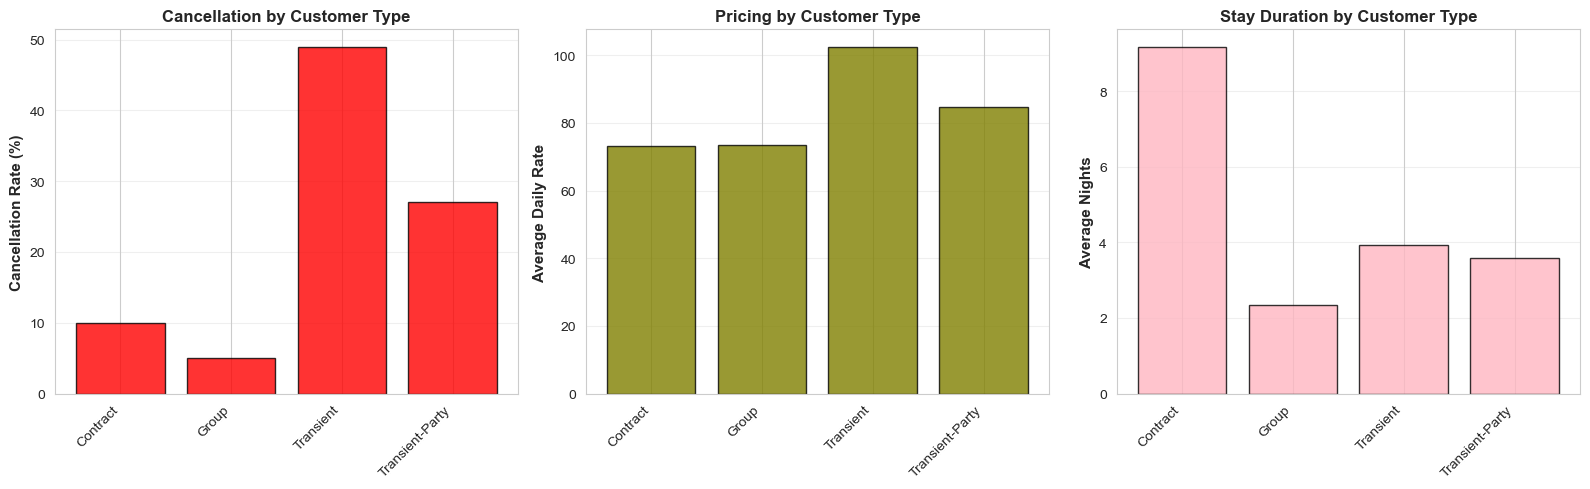

In [337]:
# Aggregate by customer classification
customer_stats = df.groupby('customer_type').agg({'is_canceled': ['count', 'mean'],'adr': 'mean','total_nights': 'mean'}).round(2)
customer_stats.columns = ['Total_Bookings', 'Cancellation_Rate', 'Avg_ADR', 'Avg_Nights']
customer_stats = customer_stats.reset_index()
customer_stats['Cancel_Rate_%'] = (customer_stats['Cancellation_Rate'] * 100).round(1)

print("\nCustomer Type Patterns:")
print(customer_stats[['customer_type', 'Total_Bookings', 
                      'Cancel_Rate_%', 'Avg_ADR', 'Avg_Nights']].to_string(index=False))

# VISUALIZATION: Customer Type Comparison (Multi-panel)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Chart 1: Cancellation rates
axes[0].bar(range(len(customer_stats)), customer_stats['Cancel_Rate_%'], color='red', edgecolor='black', alpha=0.8)
axes[0].set_ylabel('Cancellation Rate (%)', fontweight='bold', fontsize=11)
axes[0].set_title('Cancellation by Customer Type', fontweight='bold')
axes[0].set_xticks(range(len(customer_stats)))
axes[0].set_xticklabels(customer_stats['customer_type'], rotation=45, ha='right')
axes[0].grid(axis='y', alpha=0.3)

# Chart 2: ADR
axes[1].bar(range(len(customer_stats)), customer_stats['Avg_ADR'], color='olive', edgecolor='black', alpha=0.8)
axes[1].set_ylabel('Average Daily Rate', fontweight='bold', fontsize=11)
axes[1].set_title('Pricing by Customer Type', fontweight='bold')
axes[1].set_xticks(range(len(customer_stats)))
axes[1].set_xticklabels(customer_stats['customer_type'], rotation=45, ha='right')
axes[1].grid(axis='y', alpha=0.3)

# Chart 3: Stay duration
axes[2].bar(range(len(customer_stats)), customer_stats['Avg_Nights'], color='lightpink', edgecolor='black', alpha=0.8)
axes[2].set_ylabel('Average Nights', fontweight='bold', fontsize=11)
axes[2].set_title('Stay Duration by Customer Type', fontweight='bold')
axes[2].set_xticks(range(len(customer_stats)))
axes[2].set_xticklabels(customer_stats['customer_type'], rotation=45, ha='right')
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


**Interpretation:** 

Group (5.0%) and contract (10.0%) customers provide best retention. Contract guests stay longest (9.17 nights), reflecting corporate housing agreements, while groups book short-term events (2.35 nights). Individual transient travelers dominate volume but show highest cancellation (49.0%) despite premium pricing. Hotels should develop group and corporate contract relationships for stable revenue.



### 4.7 Deposit Policy Impact



Deposit Type Impact:
deposit_type  Total_Bookings  Cancel_Rate_%
  No Deposit           23480           44.8
  Non Refund             391           94.6
  Refundable              79            5.1


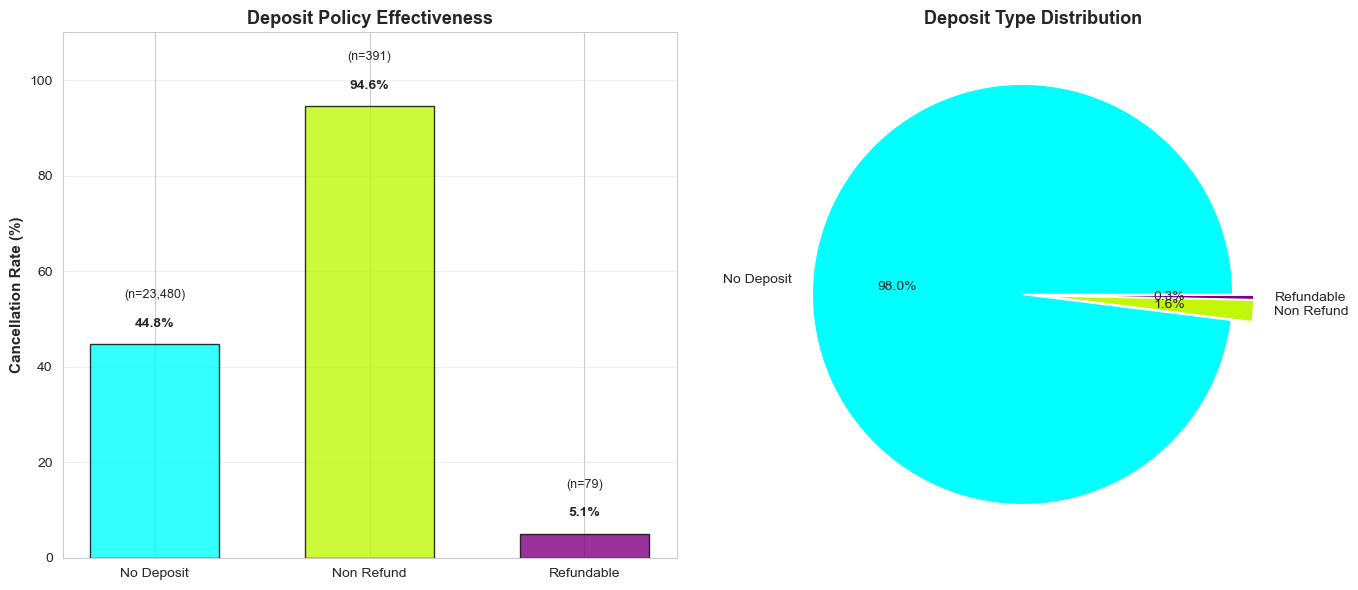

In [338]:
# Aggregate by deposit type
deposit_stats = df.groupby('deposit_type').agg({'is_canceled': ['count', 'mean']}).round(3)
deposit_stats.columns = ['Total_Bookings', 'Cancellation_Rate']
deposit_stats = deposit_stats.reset_index()

deposit_stats['Cancel_Rate_%'] = (deposit_stats['Cancellation_Rate'] * 100).round(1)

print("\nDeposit Type Impact:")
print(deposit_stats[['deposit_type', 'Total_Bookings', 'Cancel_Rate_%']].to_string(index=False))

# VISUALIZATION: Deposit Policy Effectiveness

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Bar chart - Cancellation rates 
bars = ax1.bar(deposit_stats['deposit_type'], 
              deposit_stats['Cancel_Rate_%'],
              color=['#00FFFF', '#C1F80A', '#800080'], 
              edgecolor='black', alpha=0.8, width=0.6)

ax1.set_ylabel('Cancellation Rate (%)', fontweight='bold', fontsize=11)
ax1.set_title('Deposit Policy Effectiveness', fontweight='bold', fontsize=13)
ax1.set_ylim(0, 110)

# Add labels with proper spacing
for bar, row in zip(bars, deposit_stats.itertuples()):
    height = bar.get_height()
  
    ax1.text(bar.get_x() + bar.get_width()/2., height + 3, f'{height:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=10)
    ax1.text(bar.get_x() + bar.get_width()/2., height + 9, f'(n={row.Total_Bookings:,})', ha='center', va='bottom', fontsize=9)

ax1.grid(axis='y', alpha=0.3)

# Pie chart - Booking distribution
ax2.pie(deposit_stats['Total_Bookings'], 
       labels=deposit_stats['deposit_type'],
       autopct='%1.1f%%', 
       explode=(0.05, 0.05, 0.05),
       colors=['#00FFFF', '#C1F80A', '#800080'])
ax2.set_title('Deposit Type Distribution', fontweight='bold', fontsize=13)

plt.tight_layout()
plt.show()


**Interpretation:** 

Refundable deposits achieve lowest cancellation (5.1%), while non-refundable show highest (94.6%)—counterintuitive pattern likely reflects hotel-initiated cancellations rather than customer abandonment. Refundable deposits' low cancellation suggests committed corporate/group bookings with cancellation flexibility. Hotels should expand refundable deposit options for corporate clients.


### 4.8 Relationship Analysis - HEXBIN DENSITY PLOTS

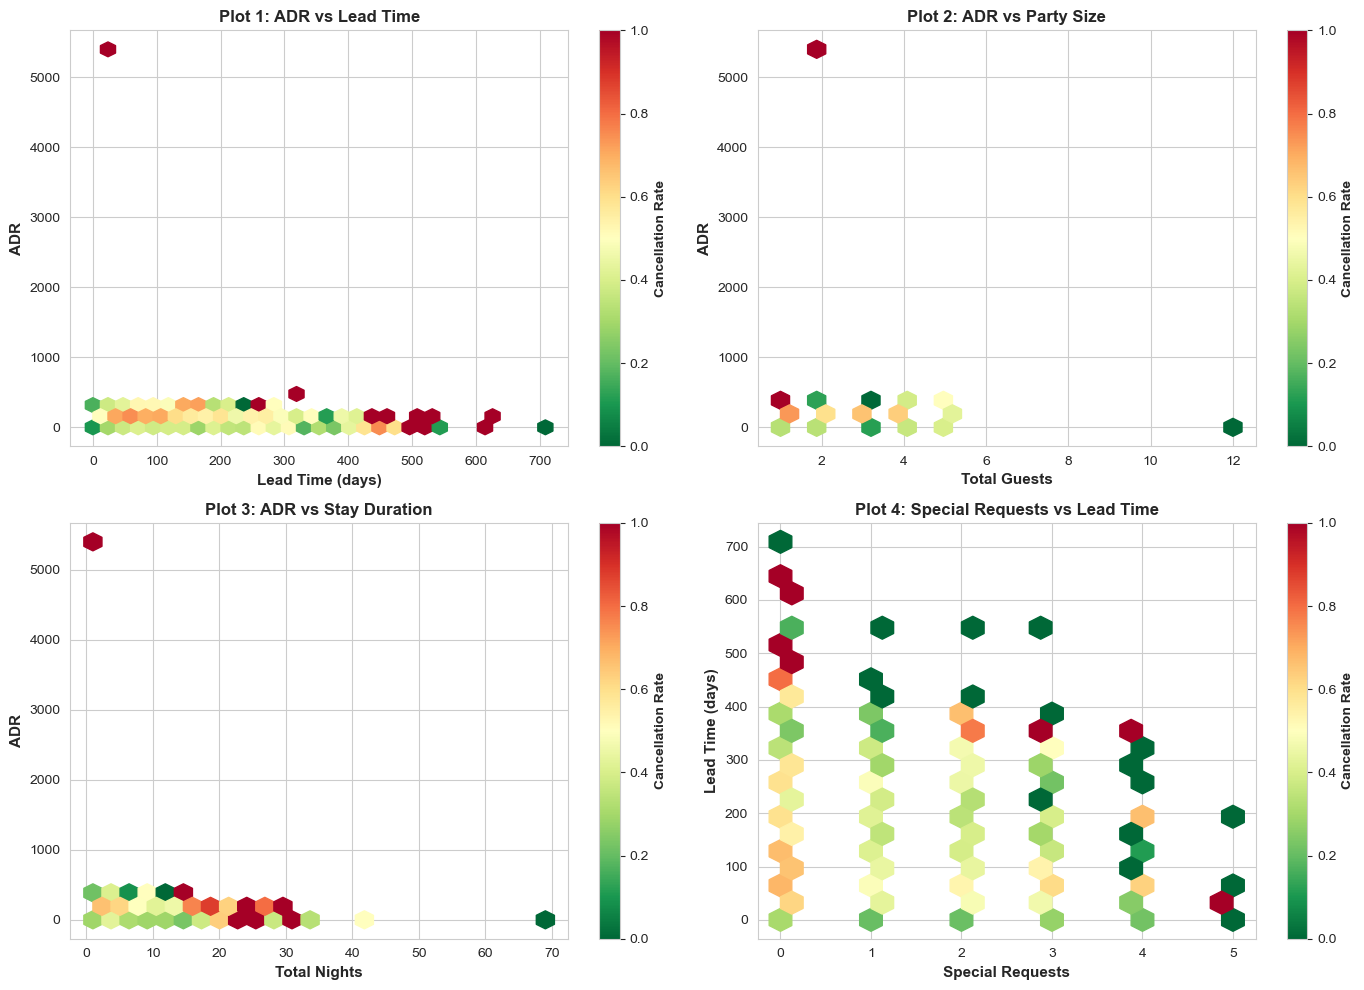

In [339]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: ADR vs Lead Time
im1 = axes[0,0].hexbin(df['lead_time'], df['adr'], C=df['is_canceled'], gridsize=30, cmap='RdYlGn_r', reduce_C_function=np.mean, mincnt=1)
axes[0,0].set_xlabel('Lead Time (days)', fontweight='bold', fontsize=11)
axes[0,0].set_ylabel('ADR', fontweight='bold', fontsize=11)
axes[0,0].set_title('Plot 1: ADR vs Lead Time', fontweight='bold', fontsize=12)
cb1 = plt.colorbar(im1, ax=axes[0,0])
cb1.set_label('Cancellation Rate', fontweight='bold')

# Plot 2: ADR vs Party Size
im2 = axes[0,1].hexbin(df['total_guests'], df['adr'], C=df['is_canceled'], gridsize=25, cmap='RdYlGn_r', reduce_C_function=np.mean, mincnt=1)
axes[0,1].set_xlabel('Total Guests', fontweight='bold', fontsize=11)
axes[0,1].set_ylabel('ADR', fontweight='bold', fontsize=11)
axes[0,1].set_title('Plot 2: ADR vs Party Size', fontweight='bold', fontsize=12)
cb2 = plt.colorbar(im2, ax=axes[0,1])
cb2.set_label('Cancellation Rate', fontweight='bold')

# Plot 3: ADR vs Stay Duration
im3 = axes[1,0].hexbin(df['total_nights'], df['adr'], C=df['is_canceled'], gridsize=25, cmap='RdYlGn_r', reduce_C_function=np.mean, mincnt=1)
axes[1,0].set_xlabel('Total Nights', fontweight='bold', fontsize=11)
axes[1,0].set_ylabel('ADR', fontweight='bold', fontsize=11)
axes[1,0].set_title('Plot 3: ADR vs Stay Duration', fontweight='bold', fontsize=12)
cb3 = plt.colorbar(im3, ax=axes[1,0])
cb3.set_label('Cancellation Rate', fontweight='bold')

# Plot 4: Special Requests vs Lead Time
im4 = axes[1,1].hexbin(df['total_of_special_requests'], df['lead_time'], C=df['is_canceled'], gridsize=20, cmap='RdYlGn_r', reduce_C_function=np.mean,
                       mincnt=1)
axes[1,1].set_xlabel('Special Requests', fontweight='bold', fontsize=11)
axes[1,1].set_ylabel('Lead Time (days)', fontweight='bold', fontsize=11)
axes[1,1].set_title('Plot 4: Special Requests vs Lead Time', fontweight='bold', fontsize=12)
cb4 = plt.colorbar(im4, ax=axes[1,1])
cb4.set_label('Cancellation Rate', fontweight='bold')

plt.tight_layout()
plt.show()


**Interpretation:** 

Hexbin density reveals cancellation risk patterns. Plot 1 shows high cancellation (red) at extreme lead times (300-700 days) regardless of price. Plots 2 and 3 demonstrate party size and stay duration have minimal impact on cancellation, uniform color patterns across all values. Plot 4 identifies the key predictor: bookings with 0-1 special requests at long lead times (400+ days) show high cancellation (red), while 2+ requests at shorter lead times retain better (green). Special requests signal commitment. Require deposits for bookings with 100+ day lead times and fewer than 2 special requests.

### 4.9 Correlation Matrix


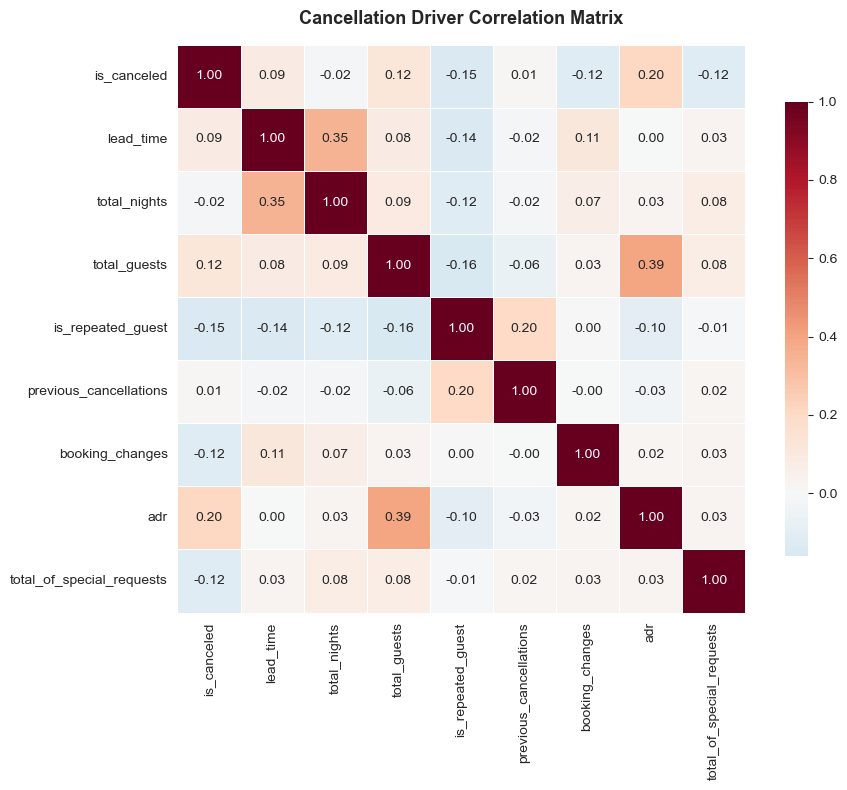


Top Cancellation Correlations:
is_canceled               1.000000
adr                       0.204022
total_guests              0.124293
lead_time                 0.088985
previous_cancellations    0.011771
total_nights             -0.020662
Name: is_canceled, dtype: float64


In [340]:
# Select relevant numerical features for correlation analysis
corr_vars = ['is_canceled', 'lead_time', 'total_nights', 'total_guests',
             'is_repeated_guest', 'previous_cancellations', 'booking_changes',
             'adr', 'total_of_special_requests']

# Calculate correlation matrix
corr_matrix = df[corr_vars].corr()

# VISUALIZATION: Correlation Heatmap

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Cancellation Driver Correlation Matrix', fontweight='bold', fontsize=13, pad=15)
plt.tight_layout()
plt.show()

# Display top correlations with cancellation
cancel_corr = corr_matrix['is_canceled'].sort_values(ascending=False)
print("\nTop Cancellation Correlations:")
print(cancel_corr.head(6))


**Interpretation:** 

ADR shows strongest correlation (0.20)—premium pricing moderately increases cancellation risk. Repeat guests (-0.15) and special requests (-0.12) provide protective effects, confirming loyalty and engagement reduce abandonment. Surprisingly, previous cancellations (0.01) show no predictive value. Weak correlations indicate cancellation is multifactorial, requiring combined risk assessment.


### 4.10 Temporal Patterns (Monthly Trends)

,Year,Month,Bookings,Cancel_Rate,Avg_ADR
0,2016,January,1240,21.05%,59.84
1,2016,February,1596,30.70%,61.37
2,2016,March,2252,37.74%,74.03
3,2016,April,2217,44.34%,84.81
4,2016,May,2198,41.86%,91.74
5,2016,June,1840,48.32%,109.87
6,2016,July,2064,51.55%,145.01
7,2016,August,2526,56.41%,168.26
8,2016,September,2039,51.79%,119.25
9,2016,October,2384,49.62%,87.83


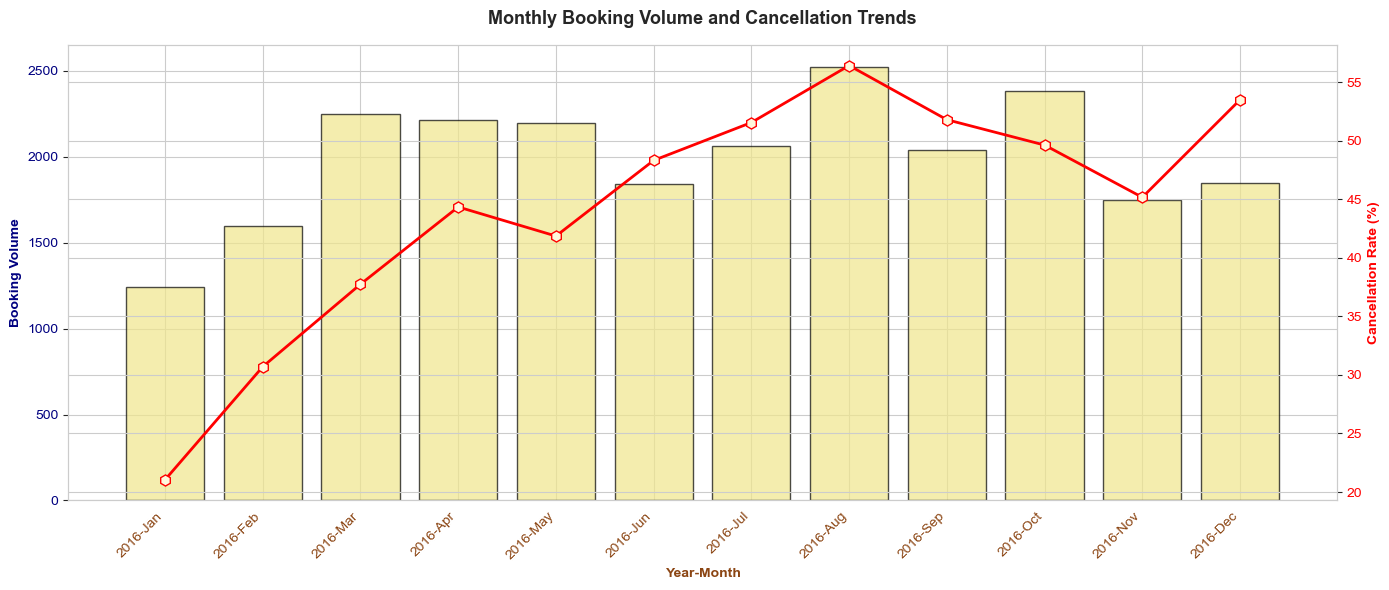

In [341]:
# TIME SERIES - MONTHLY PATTERNS

# Create year-month column
df['arrival_year_month'] = df['arrival_date_year'].astype(str) + '-' + \
df['arrival_date_month']

# Define month order
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

# Aggregate by month
monthly_stats = df.groupby(['arrival_date_year', 'arrival_date_month']).agg({
    'is_canceled': ['count', 'mean'], 'adr': 'mean'}).reset_index()

monthly_stats.columns = ['Year', 'Month', 'Bookings', 'Cancel_Rate', 'Avg_ADR']
monthly_stats['Month'] = pd.Categorical(monthly_stats['Month'], categories=month_order, ordered=True)

# Sort data and create a clean sequential index
monthly_stats = monthly_stats.sort_values(['Year', 'Month']).reset_index(drop=True)

# Display monthly statistics with formatting and color styling
display(monthly_stats.style.format({'Cancel_Rate': "{:.2%}", 'Avg_ADR': "{:.2f}"})
      
.background_gradient(subset=['Bookings'], cmap='YlGnBu')
.background_gradient(subset=['Cancel_Rate'], cmap='Reds')
.background_gradient(subset=['Avg_ADR'], cmap='Purples')
      
.set_caption("Monthly Booking Statistics"))

# Create period index for x-axis
monthly_stats['Period'] = range(len(monthly_stats))

# VISUALIZATION: Monthly Volume and Cancellation Trends

fig, ax1 = plt.subplots(figsize=(14, 6))

# Booking volume
ax1.bar(monthly_stats['Period'], monthly_stats['Bookings'], alpha=0.7, color='khaki', edgecolor='black', label='Bookings')
ax1.set_xlabel('Year-Month', fontweight='bold', color='saddlebrown')
ax1.set_ylabel('Booking Volume', fontweight='bold', color='navy')
ax1.tick_params(axis='y', labelcolor='navy')

# Cancellation rate
ax2 = ax1.twinx()
ax2.plot(monthly_stats['Period'], monthly_stats['Cancel_Rate'] * 100,
        color='red', marker='h', markerfacecolor='cornsilk', markersize=8, linewidth=2, label='Cancel Rate')
ax2.set_ylabel('Cancellation Rate (%)', fontweight='bold', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Set x-axis labels
ax1.set_xticks(monthly_stats['Period'])
ax1.set_xticklabels([f"{row.Year}-{row.Month[:3]}" for row in monthly_stats.itertuples()], rotation=45, ha='right', color='saddlebrown')

plt.title('Monthly Booking Volume and Cancellation Trends', fontweight='bold', fontsize=13, pad=15)
fig.tight_layout()
plt.show()


**Interpretation:** 

Booking volume peaks in August (2,500 bookings) during summer season, with corresponding high cancellation rate (56%). January shows lowest activity (1,250 bookings) and lowest cancellation (21%). Cancellation rates range from 21-56% across the year, demonstrating strong seasonal variation. December shows notable spike to 54% cancellation despite moderate volume. Both booking volume and cancellation risk follow seasonal patterns, requiring month-specific pricing and deposit strategies—particularly strict policies for high-risk summer months.

## 5. Conclusion and Next Steps

This analysis identifies critical cancellation drivers requiring strategic intervention.  

**Key findings:** Online travel agencies (59% cancellation) versus corporate/direct channels (20-23%) demonstrates a 35+ percentage point retention gap. Lead time shows non-linear risk peaking at 58.8% for 31-90 day advance bookings. Groups (5%) and contracts (10%) provide exceptional retention. Non-refundable deposits' 94.6% cancellation suggests hotel-initiated cancellations requiring policy review.

**Immediate recommendations:** Implement tiered deposit policy (50% non-refundable for 31-180 day bookings), increase OTA commission 3-5% to offset risk, launch direct booking incentives (10-15% discount).  

**Advanced analytics:** Deploy machine learning classification model combining lead time, channel, customer type, and special requests for real-time risk scoring.  

**Strategic initiatives:** Expand corporate partnerships (target 500+ stable bookings annually), develop group segment (current 5% cancellation), implement length-of-stay pricing for 7+ nights.

**Limitations:** Single-year 2016 data limits trend validation. Future research should incorporate multi-year analysis (2016-2025), COVID-19 impact, post-cancellation surveys differentiating customer versus hotel-initiated cancellations, and experimental A/B testing of deposit policies.
